In [21]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib import colors as mcolors

import scanpy as sc
import squidpy as sq
import cellcharter as cc
import scvi

from pandas.api.types import is_numeric_dtype, is_categorical_dtype
from scipy.sparse import issparse

import sys
sys.path.append("/Users/christoffer/work/karolinska/development/MANA")
from utils.plot_spatial_compact_fast import plot_spatial_compact_fast
from utils import aggregate_neighbors_weighted



In [22]:
import h5py

# Update this path to the file you want to read
H5AD_PATH = '/Volumes/processing2/oligo-mtDSB/data/mtDNA_DSB_5k_clustered_annotation_with_rbd_2_cytetype_brain_novae.h5ad'

def _collect_bad_datasets(g, prefix=""):
    bad = []
    for key, obj in g.items():
        path = f"{prefix}/{key}" if prefix else key
        if isinstance(obj, h5py.Group):
            bad.extend(_collect_bad_datasets(obj, path))
        elif isinstance(obj, h5py.Dataset):
            enc_type = obj.attrs.get('encoding_type', None)
            if enc_type in (None, 'null'):
                bad.append(path)
    return bad

# Remove datasets under /uns with missing or null encoding_type
with h5py.File(H5AD_PATH, 'r+') as f:
    if 'uns' in f:
        bad = _collect_bad_datasets(f['uns'], 'uns')
        for path in bad:
            del f[path]
        print(f'Removed {len(bad)} datasets with encoding_type null/missing under /uns')
        if bad:
            print('Examples:', bad[:5])


Removed 0 datasets with encoding_type null/missing under /uns


# adding raw data to object

In [27]:
ad_sub = sc.read_h5ad(H5AD_PATH)


In [28]:
ad_sub.obs

,x_centroid,y_centroid,transcript_counts,control_probe_counts,genomic_control_counts,control_codeword_counts,unassigned_codeword_counts,deprecated_codeword_counts,total_counts,cell_area,...,cytetype_annotation_leiden_3,cytetype_cellOntologyTerm_leiden_3,novae_sid,neighborhood_valid,novae_leaves,novae_domains_15,novae_domains_30,novae_domains_25,novae_domains_20,novae_domains_50
aaaaakjg-1,67.136543,1092.286377,631,0,0,0,1,0,631.0,37.434533,...,Mature Myelinating Oligodendrocyte (progenitor...,CL_4072003,RB4282,True,D261,D1001,D986,D986,D1001,D973
aaaaikjn-1,80.635910,779.488647,1102,0,0,0,2,0,1102.0,90.538285,...,Layer 5 Cortical Excitatory Neuron,CL_4023041,RB4282,True,D160,D1001,D992,D992,D1001,D969
aaaapoln-1,67.554489,1513.168579,335,0,0,0,0,0,335.0,20.817032,...,Cortical Excitatory Neuron (L5/6),CL_4023041,RB4282,True,D167,D1001,D986,D986,D1001,D973
aaacmkgf-1,70.575630,1138.702881,1931,0,0,0,1,0,1931.0,81.055472,...,Layer 5 Cortical Excitatory Neuron,CL_4023041,RB4282,True,D261,D1001,D986,D986,D1001,D973
aaaefdnf-1,583.425537,1142.197876,1105,0,0,0,1,0,1105.0,68.276252,...,Mature Myelinating Oligodendrocyte (myelin pro...,CL_4301614,RB4282,True,D205,D1001,D986,D986,D1001,D973
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
oifndkbo-1,2379.717529,4785.681152,419,0,0,0,0,0,419.0,42.221095,...,Thalamic Astrocyte,CL_0012000,RB4676,True,D442,D1005,D976,D997,D997,D952
oifolalk-1,2281.881104,4803.725098,219,0,0,0,0,0,219.0,36.170158,...,Hypothalamic GABAergic Neuron,CL_0000617,RB4676,True,D400,D1003,D975,D998,D1003,D920
oifphdni-1,2343.403564,4830.252441,76,0,0,0,0,0,76.0,14.946719,...,Astrocyte (GABA-transporting),CL_4042007,RB4676,True,D262,D1005,D976,D997,D997,D957
oigabhlk-1,2341.813477,4843.651367,176,0,0,0,0,0,176.0,30.661095,...,Hypothalamic GABAergic Neuron,CL_0000617,RB4676,True,D71,D1005,D976,D997,D997,D952


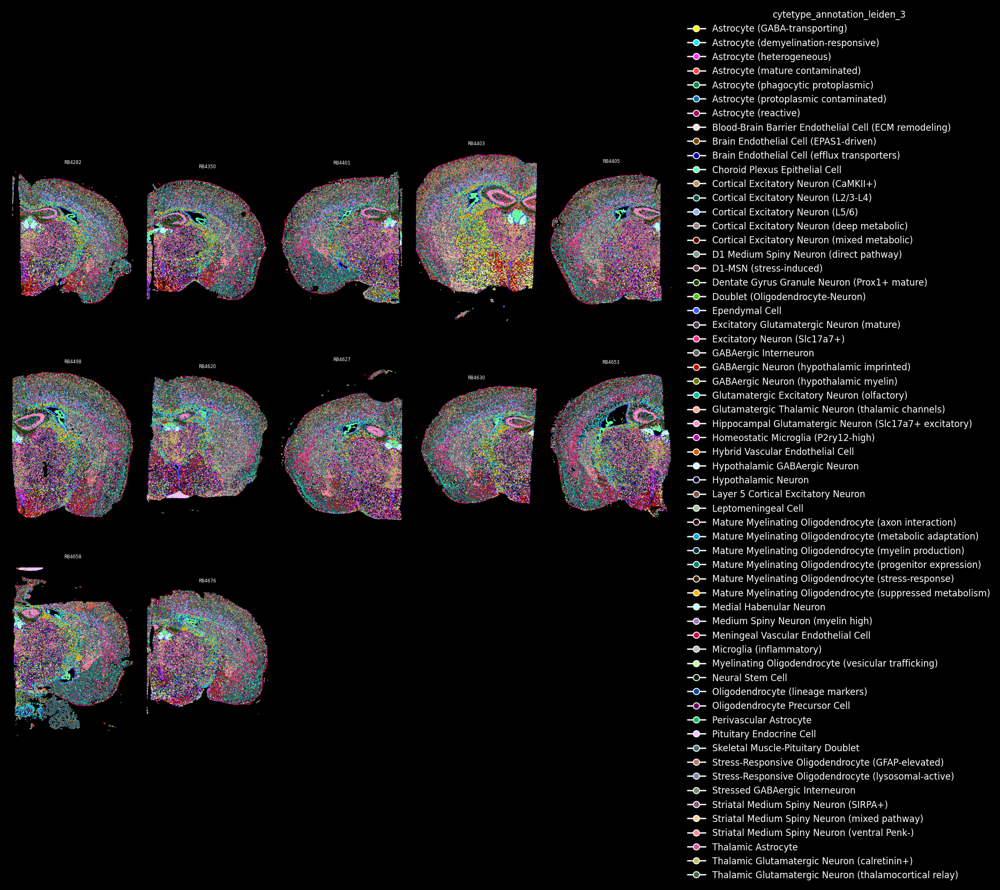

In [29]:
# usage
plot_spatial_compact_fast(
    ad_sub,
    color="cytetype_annotation_leiden_3",
    groupby="sample_id",
    spot_size=1,
    cols=5,
    height=10,
    legend_col_width=1.0,
    background="black",
    grey_alpha=0.05,
    invert_y=False,
    #highlight=['4','5']
)

In [30]:
# Ensure all layers are sparse CSR matrices
from scipy.sparse import csr_matrix, issparse

for name, layer in list(ad_sub.layers.items()):
    if not issparse(layer):
        ad_sub.layers[name] = csr_matrix(layer)

# Optional: verify
{k: type(v).__name__ for k, v in ad_sub.layers.items()}


{'counts': 'csr_matrix'}

In [35]:
ad_sub.X.toarray()

array([[0.       , 0.       , 0.       , ..., 0.8292506, 0.       ,
        0.       ],
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       ...,
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ]], shape=(980474, 5101), dtype=float32)

In [36]:
# Select HVGs to speed up scVI
sc.pp.highly_variable_genes(
    ad_sub,
    layer='counts',
    n_top_genes=250,
    flavor='seurat_v3'
)
ad_sub = ad_sub[:, ad_sub.var['highly_variable']].copy()


In [37]:
scvi.model.SCVI.setup_anndata(
    ad_sub, 
    layer="counts", 
    batch_key='sample_id',
)

model = scvi.model.SCVI(ad_sub)

In [38]:
model.train(early_stopping=True, max_epochs = 30, enable_progress_bar=True)

GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores


Epoch 30/30: 100%|██████████| 30/30 [22:14<00:00, 40.74s/it, v_num=1, train_loss_step=58.3, train_loss_epoch=53]  

`Trainer.fit` stopped: `max_epochs=30` reached.


Epoch 30/30: 100%|██████████| 30/30 [22:14<00:00, 44.49s/it, v_num=1, train_loss_step=58.3, train_loss_epoch=53]


In [42]:
ad_sub

AnnData object with n_obs × n_vars = 980474 × 250
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'run', 'n_genes_by_counts', 'n_counts', 'n_genes', 'leiden_0.5', 'leiden_1', 'leiden_2', 'cell_class', 'sample_id', 'age', 'sex', 'genotype', 'condition', 'cell_type', 'cell_id', 'rbd_domain_0.1', 'rbd_domain_0.2', 'rbd_domain_0.5', 'rbd_domain_1.0', 'RBD_compartment', 'RBD_compartment_simplified', 'leiden_1.5', 'leiden_2.1', 'leiden_2.3', 'leiden_2.5', 'leiden_3', 'cytetype_annotation_leiden_3', 'cytetype_cellOntologyTerm_leiden_3', 'novae_sid', 'neighborhood_valid', 'novae_leaves', 'novae_domains_15', 'novae_domains_30', 'novae_domains_25', 'novae_domains_20', 'novae_domains_50', '_scvi_batch', '_scvi_labels'
    var: 'n_cells_by_counts', 'mean_counts', 'pct_d

In [43]:
# Get scVI latent representation
ad_sub.obsm['X_scVI'] = model.get_latent_representation()

print(f"Added X_scVI to ad_sub.obsm with shape: {ad_sub.obsm['X_scVI'].shape}")

Added X_scVI to ad_sub.obsm with shape: (980474, 10)


In [41]:
import squidpy as sq

# Build spatial graph
# This should be done per-sample to avoid creating edges between samples
sq.gr.spatial_neighbors(
    ad_sub,
    coord_type='generic',
    delaunay=True,  # Delaunay triangulation (connects nearby cells)
    key_added='spatial',
    library_key='sample_id'  # Ensure no edges between different samples,
)

print(f"Spatial graph built: {ad_sub.obsp['spatial_connectivities'].shape}")
print(f"Average neighbors per cell: {ad_sub.obsp['spatial_connectivities'].sum(axis=1).mean():.1f}")

Spatial graph built: (980474, 980474)
Average neighbors per cell: 6.0


In [44]:
import cellcharter as cc

In [45]:
cc.gr.remove_long_links(ad_sub)

In [46]:
# Run MANA with memory-efficient per-sample processing
# Adjust 'sample_key' to match your actual sample column name!

aggregate_neighbors_weighted(
    ad_sub,
    n_layers=3,              # Optimal balance (from MANA-5)
    aggregations='mean',     # Standard aggregation
    use_rep='X_scVI',        # Use scVI latent space
    out_key='X_mana_gauss',  # Output key
    hop_decay=0.2,           # Optimal decay (from MANA-4)
    distance_kernel='gaussian',  # Winner from MANA-6 benchmark
    spatial_key='spatial',
    normalize_weights=True,
    include_self=True,
    sample_key='sample_id',  # CRITICAL: Process per-sample to avoid memory issues!
)

print("\nMANA aggregation complete!")
print(f"Output stored in adata.obsm['X_mana_gauss'] with shape: {ad_sub.obsm['X_mana_gauss'].shape}")

Processing 12 samples separately for memory efficiency...
  Processing sample 1/12: RB4282 (81,721 cells)
  Processing sample 2/12: RB4350 (72,889 cells)
  Processing sample 3/12: RB4401 (78,305 cells)
  Processing sample 4/12: RB4403 (135,378 cells)
  Processing sample 5/12: RB4405 (74,839 cells)
  Processing sample 6/12: RB4498 (75,676 cells)
  Processing sample 7/12: RB4620 (88,718 cells)
  Processing sample 8/12: RB4627 (72,848 cells)
  Processing sample 9/12: RB4630 (69,913 cells)
  Processing sample 10/12: RB4653 (77,245 cells)
  Processing sample 11/12: RB4658 (71,184 cells)
  Processing sample 12/12: RB4676 (81,758 cells)

MANA aggregation complete!
Output stored in adata.obsm['X_mana_gauss'] with shape: (980474, 40)


In [47]:
# Build neighborhood graph in MANA feature space
sc.pp.neighbors(
    ad_sub,
    use_rep='X_mana_gauss',
    n_neighbors=15,
    key_added='mana'
)

print("Neighbor graph built in MANA feature space")

Epoch 1/30:   0%|          | 0/30 [51:18<?, ?it/s]
Neighbor graph built in MANA feature space


In [48]:
resolutions = [0.5, 1.0, 1.5]

In [74]:
# Leiden clustering
# Try a few resolutions to see what works best
resolutions = [0.25]

for res in resolutions:
    key_added = f'leiden_mana_{res}'
    if key_added in ad_sub.obs.columns:
        print(f'Skipping {key_added} (already exists)')
        continue
    sc.tl.leiden(
        ad_sub,
        resolution=res,
        key_added=key_added,
        neighbors_key='mana'
    )
    n_clusters = ad_sub.obs[key_added].nunique()
    print(f'Resolution {res}: {n_clusters} clusters')


Resolution 0.25: 15 clusters


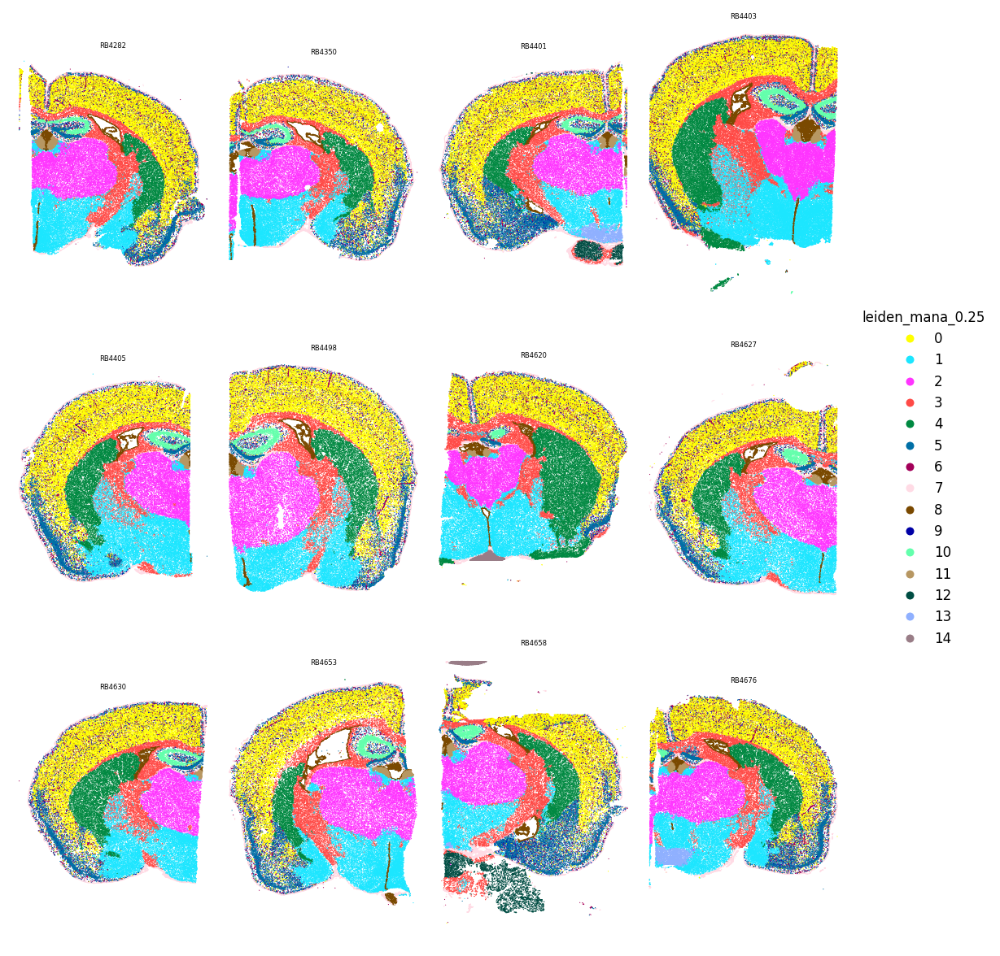

In [75]:
# Visualize MANA clustering (resolution 0.5 as starting point)
plot_spatial_compact_fast(
    ad_sub, 
    color='leiden_mana_0.25',
    groupby='sample_id',  # Adjust to your actual sample column
    spot_size = 0.5,
    cols=4,
    height=10,
    background='white',
    dpi=120,
    invert_y=False,
)

In [59]:
ad_sub.X.max()

np.float32(5.847418)

In [58]:
sc.pp.highly_variable_genes(ad_sub, n_top_genes=50, flavor='seurat_v3')


In [60]:
ad_sub.layers['normalized'] = ad_sub.X = ad_sub.X.copy()

In [73]:
ad_sub.write('/Volumes/processing2/oligo-mtDSB/data/mtDNA_DSB_5k_clustered_annotation_MANA.h5ad')

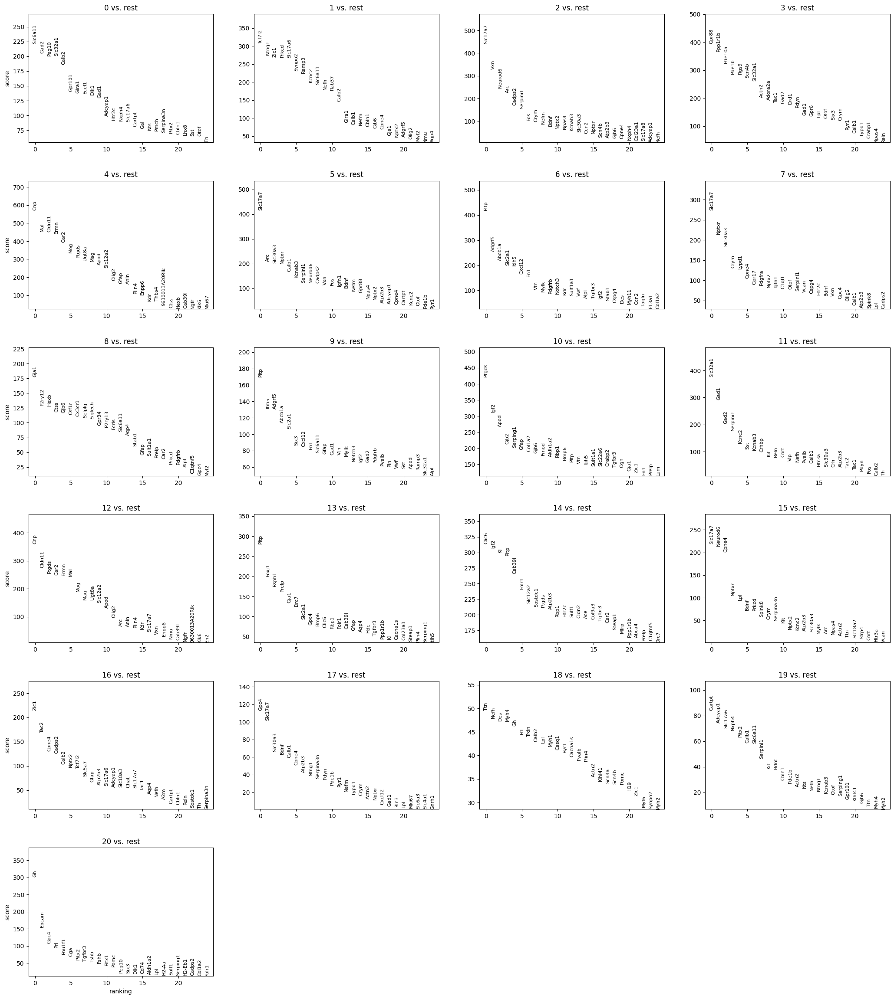

0
Slc6a11 Gad2 Peg10 Slc32a1 Calb2 Gpr101 Glra1 Ecel1 Dlk1 Gad1 Adcyap1 Htr2c Nxph4 Slc17a6 Cartpt Gal Nts Pmch Serpina3n Pitx2 Cbln1 Lhx8 Sst Otof Th Trh Tac1 Slc18a2 Lypd1 Six3
 
1
Tcf7l2 Ntng1 Zic1 Prkcd Slc17a6 Synpo2 Ramp3 Kcnc2 Slc6a11 Nefh Rab37 Calb2 Glra1 Calb1 Nefm Cbln1 Gjb6 Cpne4 Gja1 Nptx2 Adgrf5 Olig2 Myl2 Nmu Aqp4 Kdr Itih5 Mylk Igkc Abcb1a
 
2
Slc17a7 Vxn Neurod6 Arc Cadps2 Serpini1 Fos Crym Nefm Bdnf Nptx2 Npas4 Kcnab3 Slc30a3 Ccn2 Nptxr Scn4b Atp2b3 Gjb6 Cpne4 Nxph4 Col23a1 Slc17a8 Adcyap1 Nefh Ramp3 Chil3 Gzmb Cxcr2 Bglap2
 
3
Gpr88 Ppp1r1b Pde10a Pde1b Rgs9 Scn4b Slc32a1 Actn2 Adora2a Tac1 Gad2 Drd1 Pdyn Gad1 Gpr6 Lpl Otof Six3 Crym Ryr1 Calb1 Lypd1 Crabp1 Npas4 Reln Nts Gpr101 Nefm Clic6 Spink8
 
4
Cnp Mal Cldn11 Ermn Car2 Mog Ptgds Ugt8a Mag Apod Slc12a2 Olig2 Gfap Anln Plin4 Enpp6 Kdr Thbs4 9630013A20Rik Ctss Hexb Cab39l Ngfr Klk6 Mki67 Aqp4 En2 Gpr17 Nmu Serpina3n
 
5
Slc17a7 Arc Slc30a3 Nptxr Calb1 Kcnab3 Serpini1 Neurod6 Cadps2 Vxn Fos Igfn1 Bdnf Nefm Gpr88 Np

In [63]:
import pandas as pd
key = "leiden_mana_0.5"              # <-- change to your cluster column

sc.tl.rank_genes_groups(
    ad_sub,
    groupby=key,
    reference="rest",             # each group vs all other cells
    method="t-test",
    pts=True,                     # add fraction expressing
)
sc.pl.rank_genes_groups(ad_sub, n_genes=25, sharey=False)

marker_genes = pd.DataFrame({
    group: ad_sub.uns['rank_genes_groups']['names'][group][:30]
    for group in ad_sub.uns['rank_genes_groups']['names'].dtype.names
})
for col in marker_genes.columns: 
    print(col)
    genes = marker_genes[col].tolist()

    print(" ".join(genes))
    print(' ')

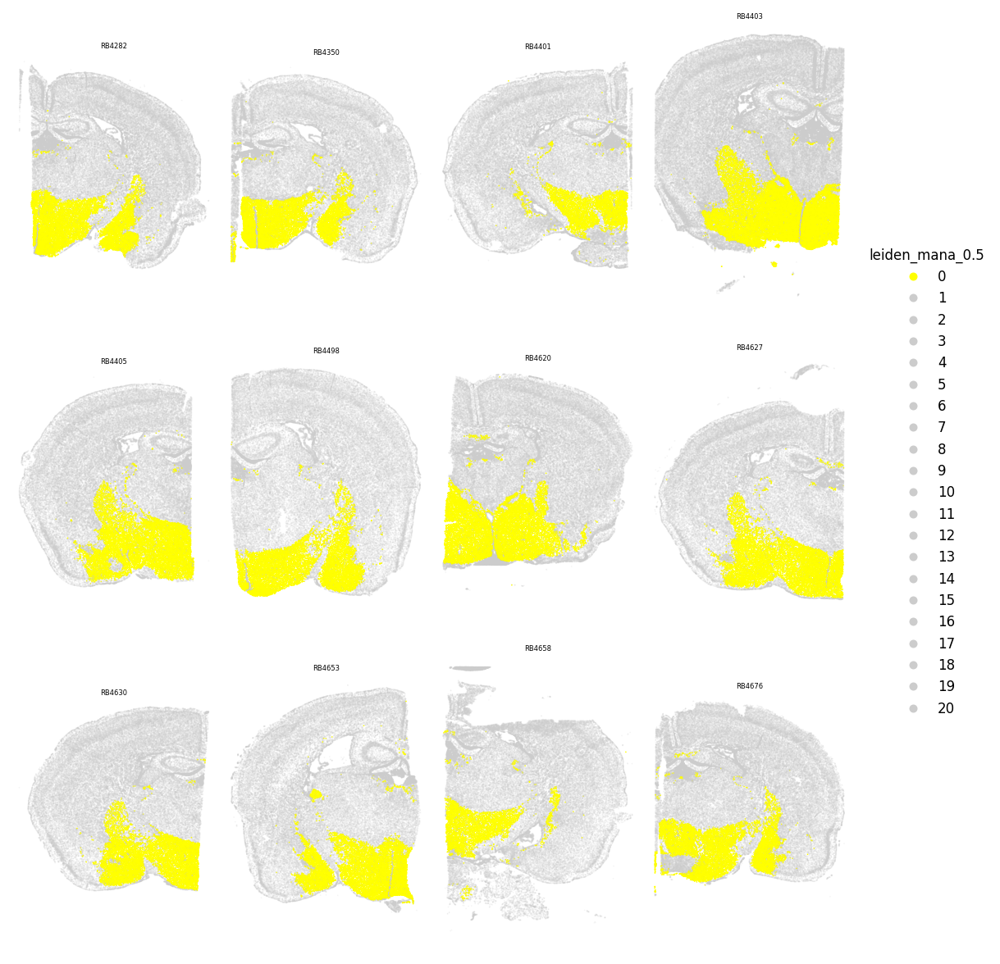

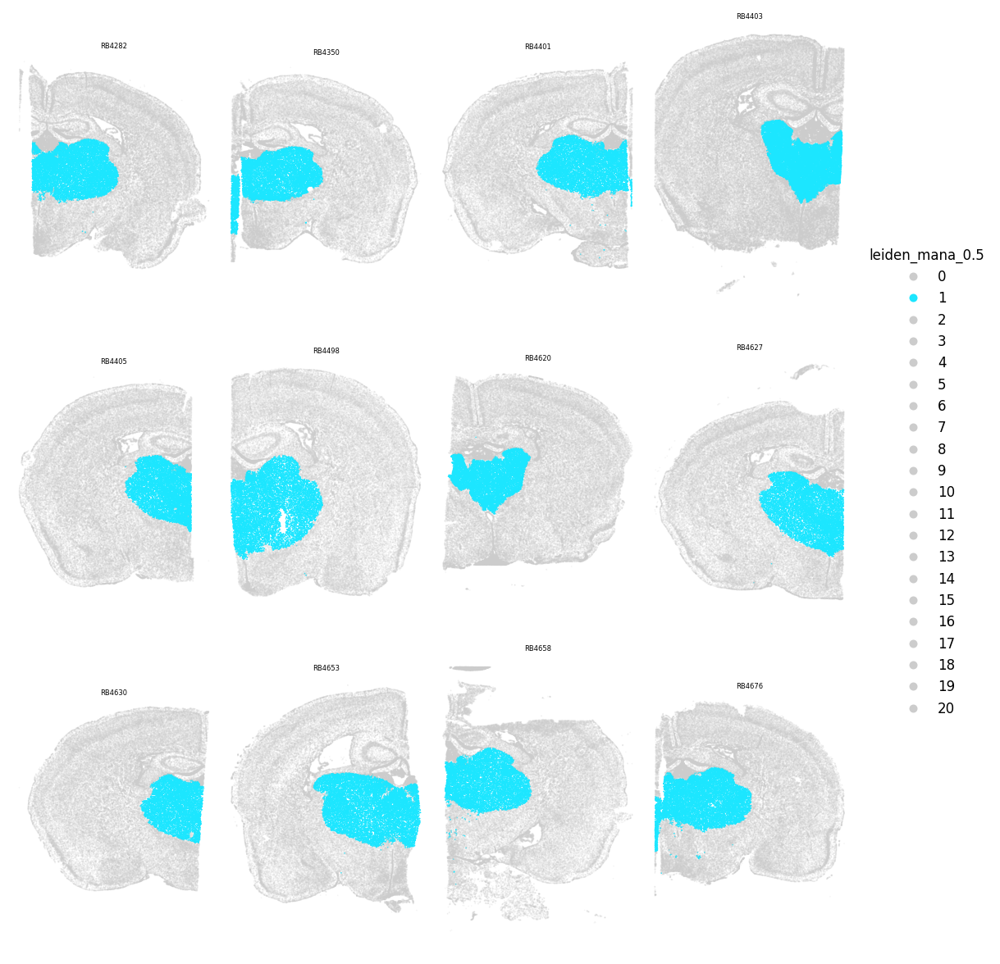

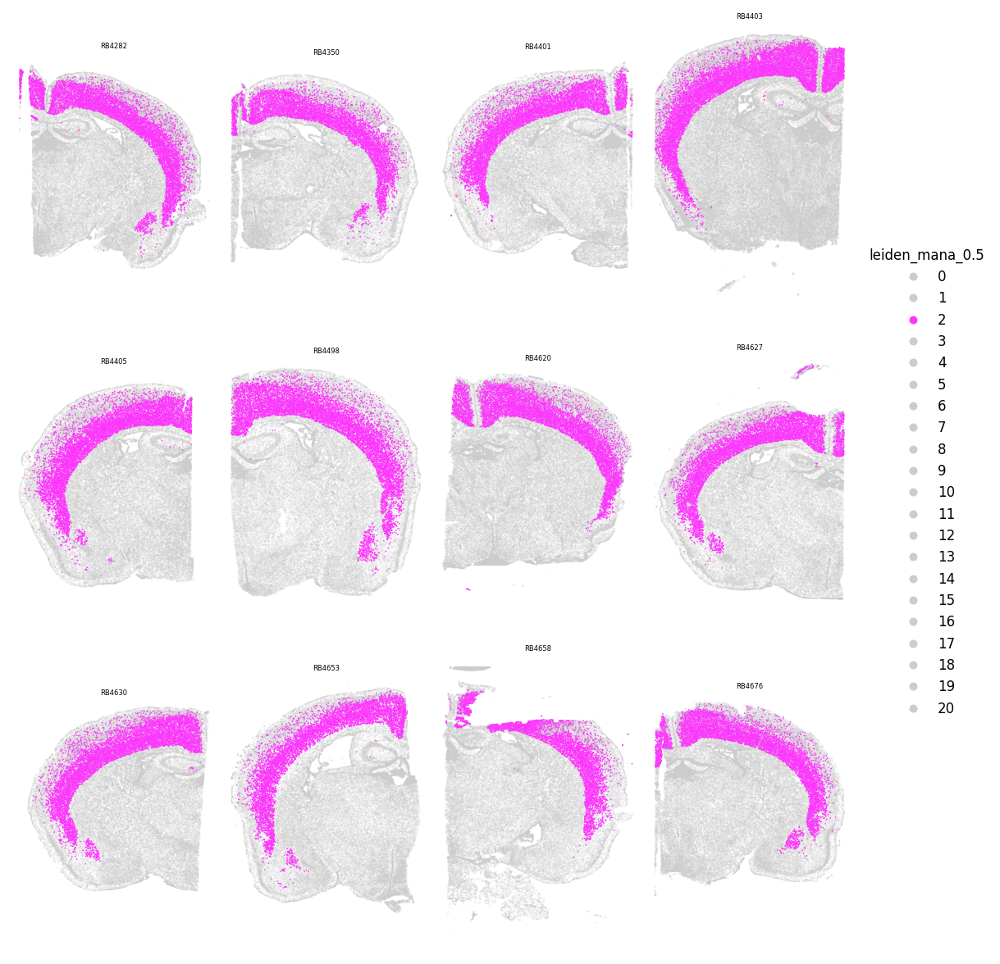

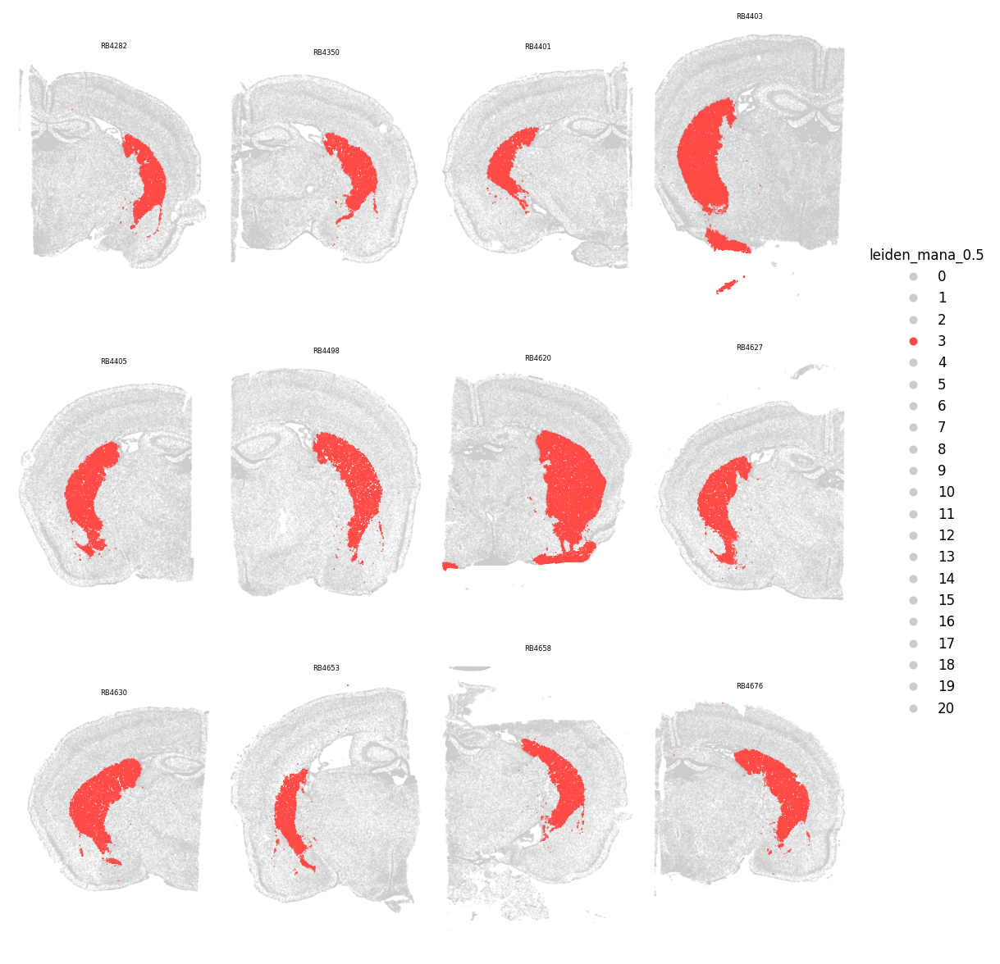

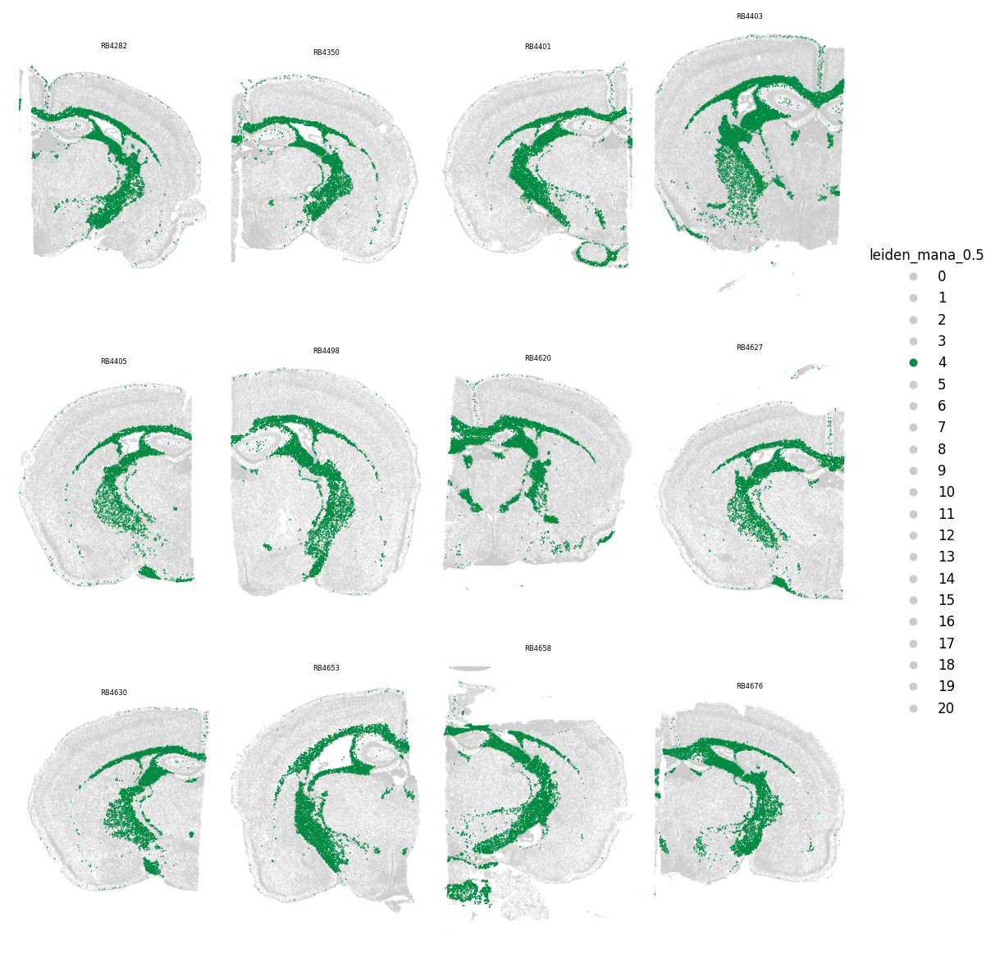

...

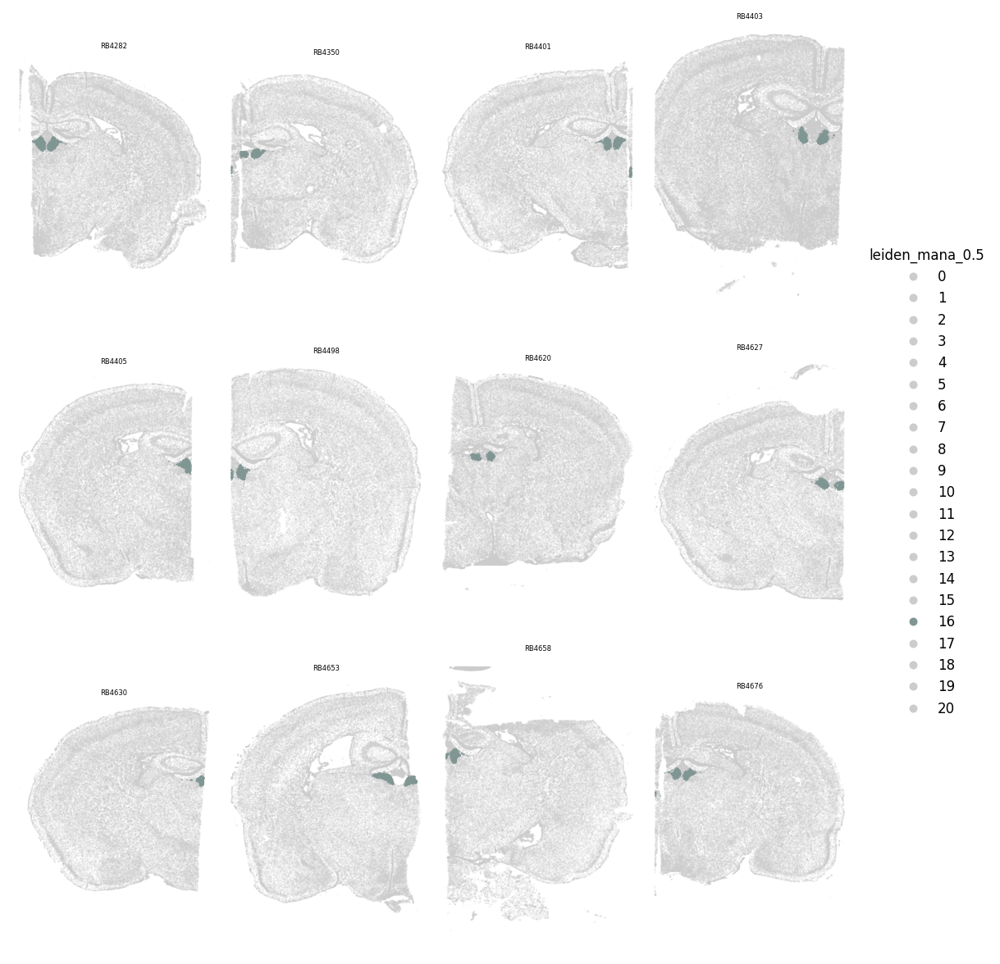

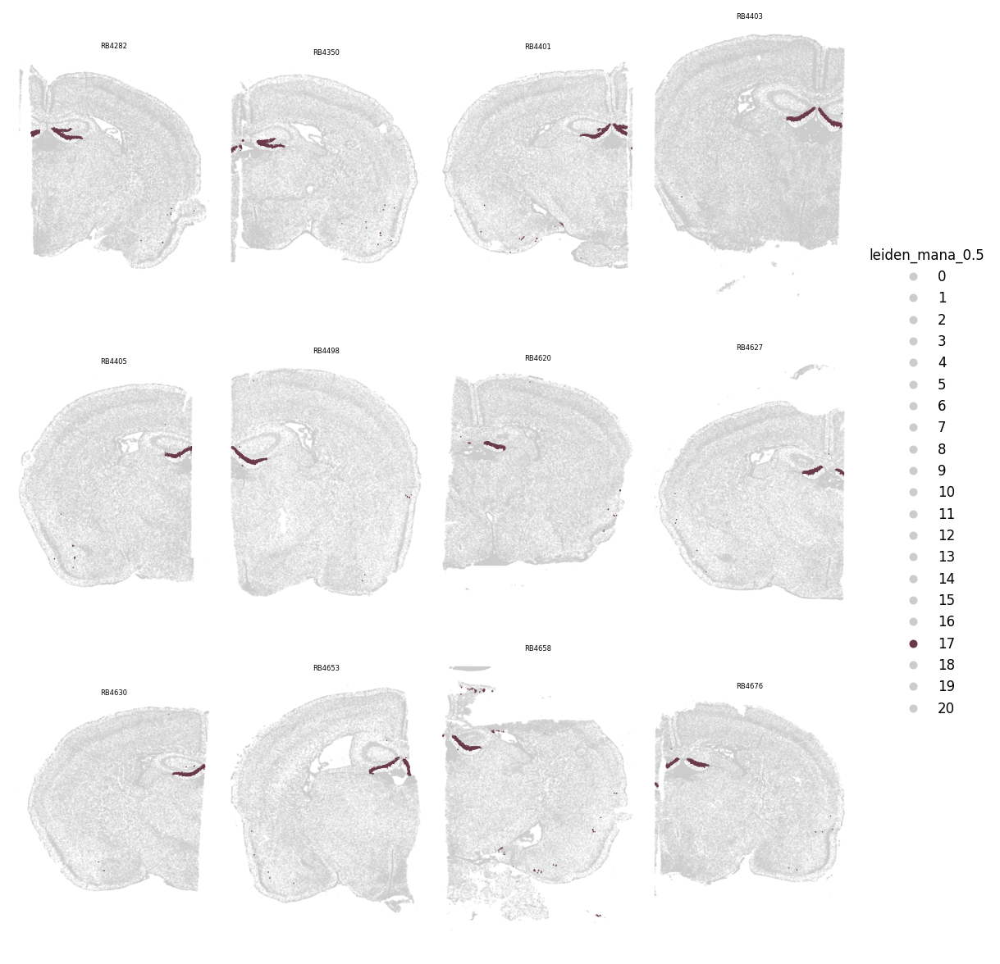

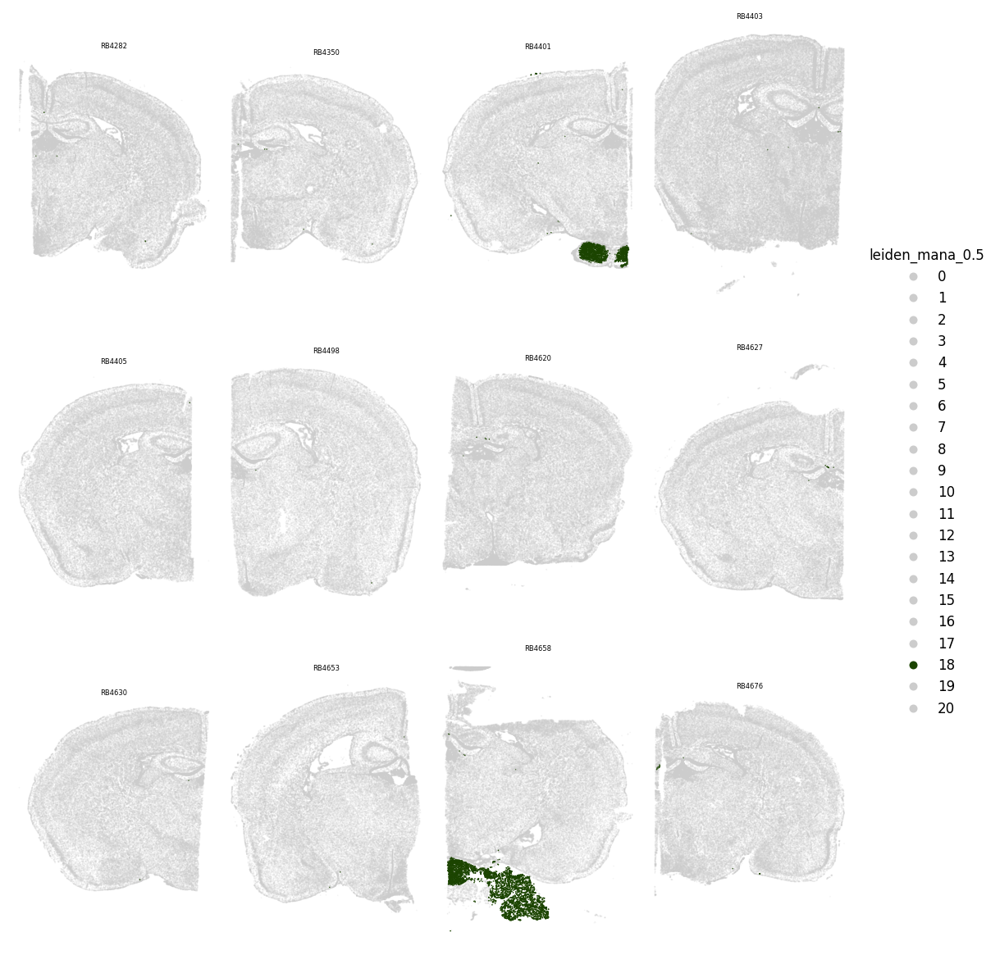

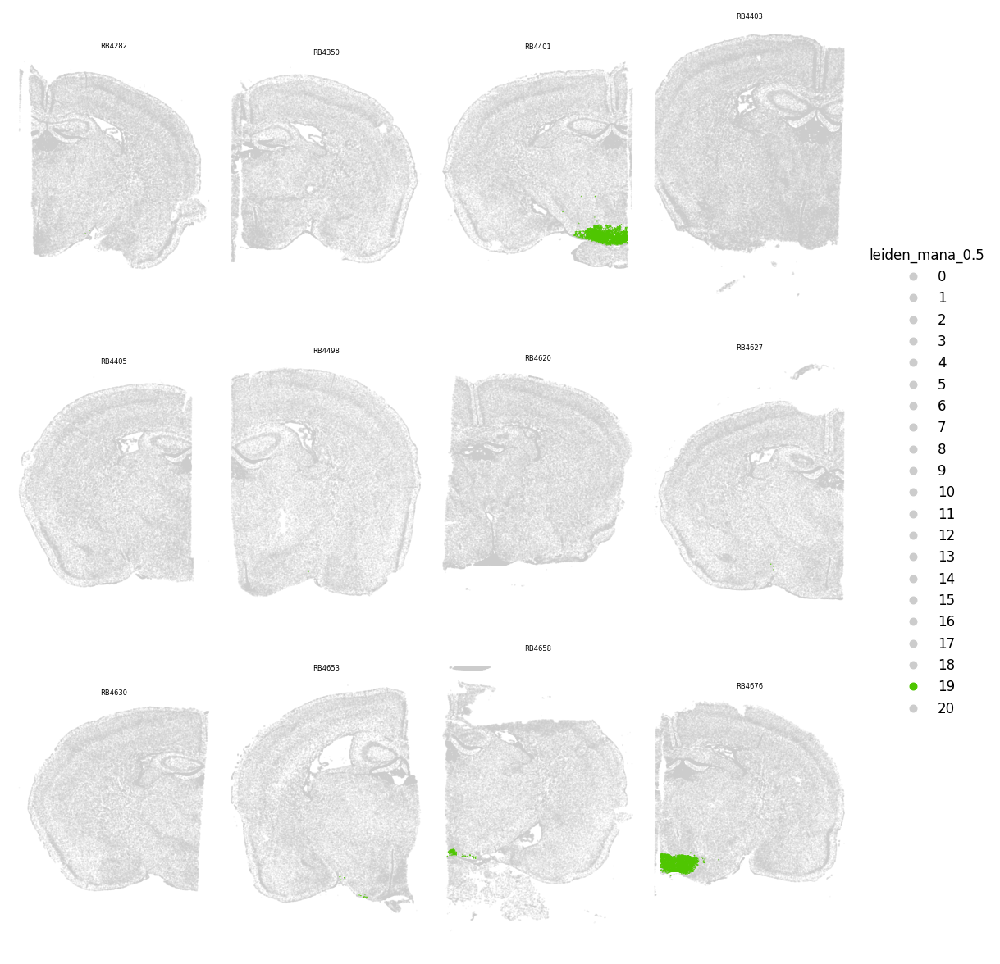

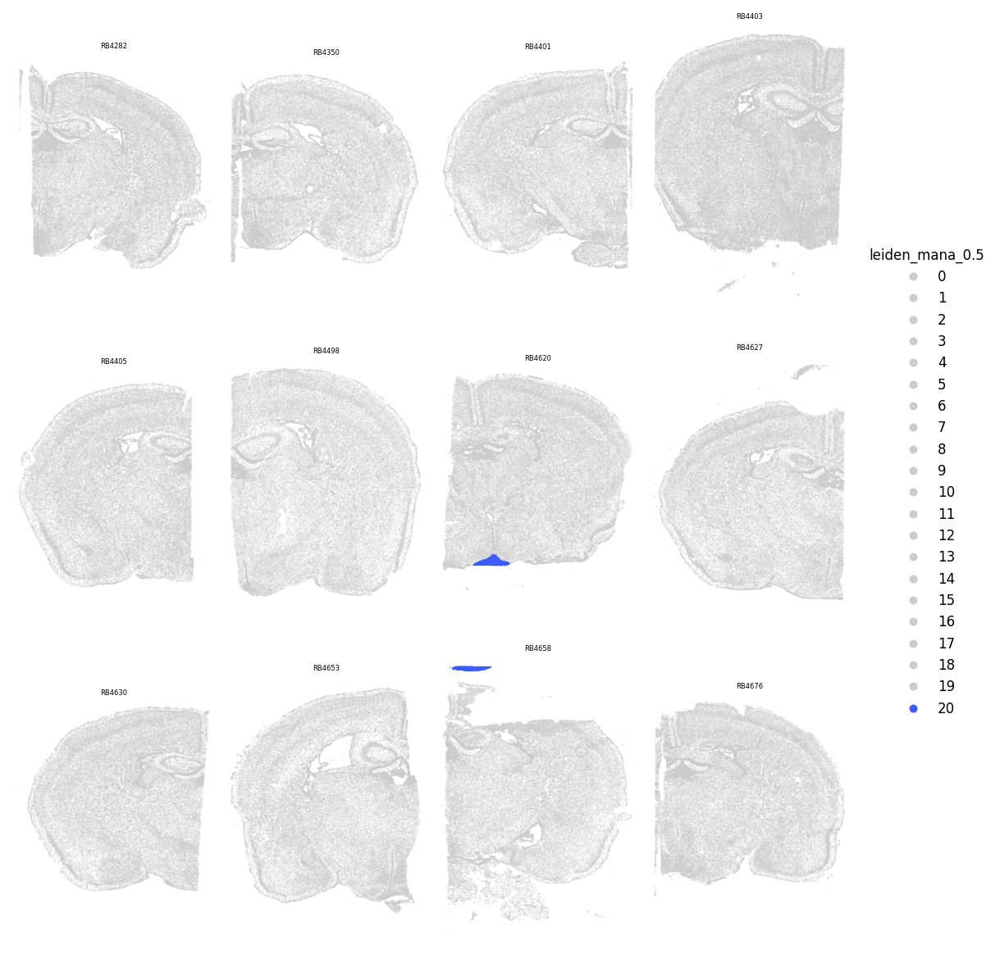

In [68]:
for compartment in sorted(ad_sub.obs['leiden_mana_0.5'].unique().astype(int)):
    plot_spatial_compact_fast(
        ad_sub, 
        color='leiden_mana_0.5',
        groupby='sample_id',  # Adjust to your actual sample column
        spot_size = 1,
        cols=4,
        height=10,
        background='white',
        dpi=120,
        invert_y=False,
        highlight=[compartment] 
    )